# Заняття 11 · Demo 4 — EKF: радар + камера за мітками часу

**LIVE DEMO 4 — слайд 42.** Спирається на слайди 40 («EKF: один стан цілі — багато асинхронних сенсорів»)
і 41 («EKF: радар і камера за мітками часу»), підсумок — слайд 43 («EKF · демо і межі»); моделі вимірювань детально — додаток, слайд 55.

Дрон перетинає поле зору щогли на 320–410 м з м'яким маневром. Радар (10 Гц): `R, az, el, v_r`. Камера (30 Гц): пікселі, f = 2000 px. Стан: `x = [p, v]` у рамці щогли.

1. Якобіан радара — пишемо і перевіряємо чисельно.
2. Чотири варіанти: лише радар, лише камера, разом, разом із хибною міткою камери.
3. Узгодженість: NEES позиції має бути ≈ 3.
4. Слайдер: зміщення мітки часу камери.
5. Gate за χ² і маневр цілі: що буде, якщо `q` занижене.

In [1]:
%matplotlib inline
import sys, numpy as np, matplotlib.pyplot as plt, ipywidgets as W
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import ekf11 as E, panels as P
P.lecture_style()                       # шрифт для проєктора, палітра Okabe–Ito


## 1. Якобіан радара
`v_r = p·v / |p|` — зверніть увагу на похідну за `v`: це одиничний вектор лінії погляду.

In [2]:
def H_radar(x):
    p, v = x[:3], x[3:]
    r = np.linalg.norm(p); rxy2 = p[0]**2 + p[1]**2; rxy = np.sqrt(rxy2)
    H = np.zeros((4, 6))
    H[0, :3] = p / r
    H[1, :2] = [-p[1] / rxy2, p[0] / rxy2]
    H[2, :3] = [-p[0] * p[2] / (r**2 * rxy), -p[1] * p[2] / (r**2 * rxy), rxy / r**2]
    H[3, :3] = v / r - (p @ v) * p / r**3
    H[3, 3:] = p / r
    return H


In [3]:
def num_jac(h, x, eps=1e-5):
    J = np.zeros((len(h(x)), len(x)))
    for i in range(len(x)):
        d = np.zeros(len(x)); d[i] = eps
        J[:, i] = (h(x + d) - h(x - d)) / (2 * eps)
    return J

x = np.array([300., 120, 50, -4, -18, 1])
print('радар, max |H − чисельний|:', np.abs(H_radar(x) - num_jac(E.h_radar, x)).max())
print('камера, max |H − чисельний|:', np.abs(E.H_cam(x) - num_jac(E.h_cam, x)).max())
E.H_radar = H_radar        # фільтр далі використовує ваш якобіан
assert np.abs(H_radar(x) - num_jac(E.h_radar, x)).max() < 1e-6


радар, max |H − чисельний|: 9.409089063439069e-10
камера, max |H − чисельний|: 6.73268596429466e-09


## 2–3. Чотири варіанти, 20 прогонів

In [4]:
res = E.summary(cam_bias=0.04)
for k, (e, n, v) in res.items():
    print(f'{k:40s} RMSE позиції {e:7.2f} м   NEES {n:6.1f} (очік. ≈ 3)   RMSE швидкості {v:5.2f} м/с')


лише радар                               RMSE позиції    3.07 м   NEES    4.8 (очік. ≈ 3)   RMSE швидкості  1.20 м/с
лише камера                              RMSE позиції  138.73 м   NEES   14.2 (очік. ≈ 3)   RMSE швидкості  8.60 м/с
радар + камера                           RMSE позиції    0.21 м   NEES    3.1 (очік. ≈ 3)   RMSE швидкості  0.32 м/с
радар + камера, мітка камери +40 мс      RMSE позиції    0.67 м   NEES   78.4 (очік. ≈ 3)   RMSE швидкості  0.31 м/с


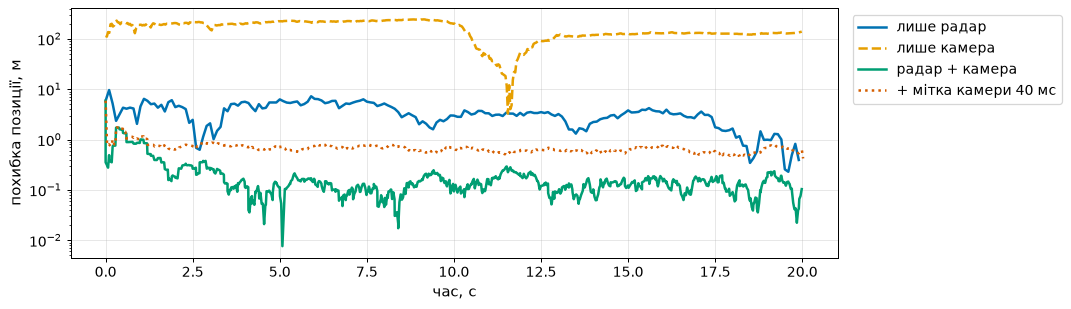

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for name, var, bias, ls in (('лише радар', 'radar', 0, '-'), ('лише камера', 'cam', 0, '--'),
                            ('радар + камера', 'fused', 0, '-'), ('+ мітка камери 40 мс', 'fused', 0.04, ':')):
    o = E.run(var, 0, bias)
    ax.semilogy(o[:, 0], o[:, 1], ls=ls, label=name)       # колір + стиль лінії: читається і без кольору
ax.set_xlabel('час, с'); ax.set_ylabel('похибка позиції, м'); ax.grid(alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.show()


## 4. Зміщення мітки часу камери — інтерактивно
При якому зміщенні NEES подвоюється? Порівняйте з бюджетом Δt на слайді «Час · бюджет» (31).

In [6]:
def show(bias_ms=0.0):
    e, n = [], []
    for s in range(8):
        o = E.run('fused', s, bias_ms / 1000)
        m = o[:, 0] > 5
        e.append(np.sqrt(np.mean(o[m, 1] ** 2))); n.append(np.mean(o[m, 2]))
    print(f'зміщення {bias_ms:4.0f} мс → RMSE {np.mean(e):.2f} м, NEES {np.mean(n):.1f}')

W.interact(show, bias_ms=W.FloatSlider(min=0, max=80, step=5, value=0, description='зміщення мітки, мс', **P.SLIDER));


interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='зміщення мітки, мс', layout…

In [7]:
for b in (0, 5, 10, 20, 40, 80):
    show(b)


зміщення    0 мс → RMSE 0.18 м, NEES 2.7


зміщення    5 мс → RMSE 0.19 м, NEES 3.1


зміщення   10 мс → RMSE 0.23 м, NEES 6.1


зміщення   20 мс → RMSE 0.35 м, NEES 19.6


зміщення   40 мс → RMSE 0.66 м, NEES 77.3


зміщення   80 мс → RMSE 1.30 м, NEES 314.2


## 5. Gate за χ² і маневр

Слайди 40–41 (цикл «predict → gate → update»): вимір з `NIS = yᵀ S⁻¹ y` вище порогу χ² (99 %: 13.3 для радара з 4 DoF, 9.21 для камери
з 2 DoF) відкидаємо без оновлення. З узгодженим фільтром так відсіюється ≈ 1 % вимірів — це хибні тривоги gate.
Ціль маневрує з 2 м/с² на 8–12 с. Якщо `q` (σ прискорення в моделі руху) менше за реальне прискорення, прогноз
відстає, NIS росте, gate відкидає вимір за виміром — і трек губиться (рядок «Маневр цілі» на слайді «EKF · демо і межі», 43; системне рішення — IMM із заняття 9). `q = 2` — уже на межі: частина
прогонів ще втрачає ціль; з `q = 3` відкидається < 1 %, але ціною гіршої точності на прямих ділянках.

q = 1 м/с²: відкинуто 16.4% вимірів, RMSE позиції  28.27 м


q = 2 м/с²: відкинуто  3.2% вимірів, RMSE позиції   2.50 м


q = 3 м/с²: відкинуто  0.8% вимірів, RMSE позиції   0.22 м


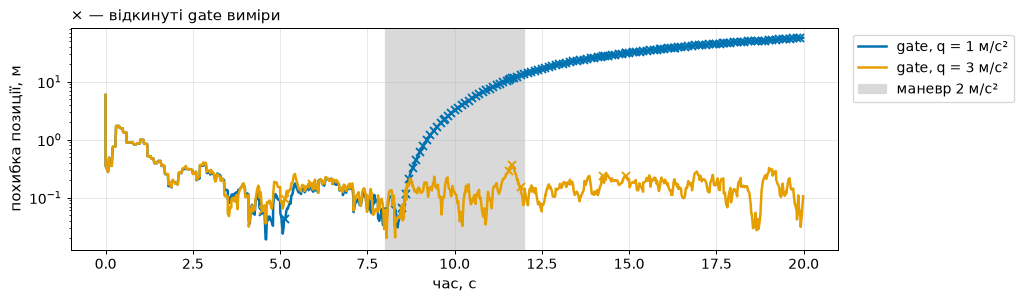

In [8]:
for q in (1.0, 2.0, 3.0):
    rej, rmse = [], []
    for s in range(20):
        o = E.run('fused', s, gate=True, q=q)
        m = o[:, 0] > 5
        rej.append(1 - o[:, 4].mean()); rmse.append(np.sqrt(np.mean(o[m, 1] ** 2)))
    print(f'q = {q:.0f} м/с²: відкинуто {np.mean(rej):5.1%} вимірів, RMSE позиції {np.mean(rmse):6.2f} м')

fig, ax = plt.subplots(figsize=(11, 3.2))
for q in (1.0, 3.0):
    o = E.run('fused', 0, gate=True, q=q)
    ax.semilogy(o[:, 0], o[:, 1], label=f'gate, q = {q:.0f} м/с²')
    ax.plot(o[o[:, 4] == 0, 0], o[o[:, 4] == 0, 1], 'x', ms=6, mew=1.5, color=ax.lines[-1].get_color())
ax.axvspan(8, 12, color='0.85', zorder=0, label='маневр 2 м/с²')
ax.set_xlabel('час, с'); ax.set_ylabel('похибка позиції, м'); ax.grid(alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('× — відкинуті gate виміри', loc='left')
plt.show()

## Питання

1. Чому «лише камера» не сходиться до істинної дальності, хоча вимірювань утричі більше, ніж радарних?
2. Чому з хибною міткою RMSE росте лише втричі, а NEES — у десятки разів? Що це означає для cue гімбала?
3. Ціль маневрує з 2 м/с² — збільште `q` у `E.run(..., q=...)`. Що відбувається з NEES і з RMSE?